<a href="https://colab.research.google.com/github/hanaabdelaal05/CS430-assignment-3/blob/main/Assignment_3_SLCM_Classification_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 3: SLCM Classification Analysis


Part 1 – Understand the Classification Problem (15 points)
1. Explore the dataset (7 points)
• Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.
• Identify one numerical and one categorical feature.
**• Answer: Why must past_due_rent be excluded from the input features?**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('/content/SLCM_rent_arrears_student_clean (1).csv')
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [5]:
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

(1754, 14)
['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']
record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64


pat_due_rent can't be an input because it is the target. using it would give answers to the model causing leakage. Meaning we would get perfect scores that aren't accurate and wouldn't mean anything,because the real question is whether other household and housing information can identify these households.

2. Create the target (8 points)
• Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.
• Show class counts and one bar chart of high_arrears.
• Answer: Which class is larger? Why might accuracy alone be misleading?

high_arrears
0    1210
1     544
Name: count, dtype: int64
high_arrears
0    0.69
1    0.31
Name: proportion, dtype: float64


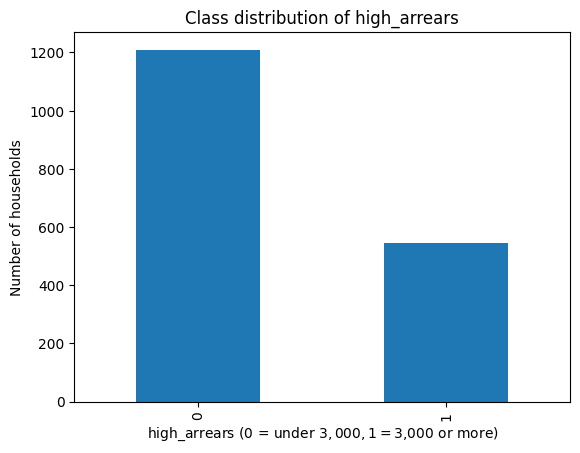

In [6]:
df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)

print(df["high_arrears"].value_counts())
print(df["high_arrears"].value_counts(normalize=True).round(3))

df["high_arrears"].value_counts().plot(kind="bar")
plt.xlabel("high_arrears (0 = under $3,000, 1 = $3,000 or more)")
plt.ylabel("Number of households")
plt.title("Class distribution of high_arrears")
plt.show()

Class 0 (under $3,000 past due) is larger, with 1,210 households (about 69%) compared with 544 households (about 31%) in class 1. Accuracy alone is not enough because a model that does nothing useful would still score about 69% just by predicting 0 every time. That model would find none of the high-arrears households, which are the ones SLCM most needs to identify. So accuracy alone can fool us, and we also need measures like recall and F1.


Part 2 – Prepare the Data (25 points)

3. Select features and split (10 points)
• Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.
• Split the data once into training and testing sets.
• Answer: Why do we keep a separate test set?

*   List item
*   List item



In [7]:
X = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(1403, 12) (351, 12)


we keep a separate test set to prevent leakage so the model can be tested on unseen data to make sure it is accurate and not overfitting.The point of the test set is to estimate how the model will do on new households it has never seen. If you scored the model on the same rows it trained on, the results would look better than they really are.

4. Build one reusable preprocessor (15 points)
• Identify numerical and categorical columns with select_dtypes.
• Numerical: fill missing values using median and apply StandardScaler.
• Categorical: fill missing values using most_frequent and apply OneHotEncoder(handle_unknown="ignore").
• Combine with ColumnTransformer. You may reuse the class example.
• Answer: Why is scaling helpful for KNN and SVC?

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print(numeric_features)
print(categorical_features)
#pipeline
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)
# Preprocessor: numeric columns -> fill with median, then scale; categorical columns -> fill with most frequent value, then one-hot encode
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)


['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


They rely on calculations where the physical scale of the features directly impacts the behavior of the model. Without scaling features with large numeric ranges will completely dominate the model.Scaling makes sure all features are treated more equally, which can improve the model's performance.

Part 3 – Train and Compare Five Models (45 points)


5. Train the five classifiers (20 points)
• Build five pipelines with the same preprocessor, the same training set, and these models:
• Logistic Regression: LogisticRegression(max_iter=1000)
• KNN: KNeighborsClassifier(n_neighbors=5)
• Decision Tree: DecisionTreeClassifier(max_depth=5, random_state=42)
• Random Forest: RandomForestClassifier(n_estimators=100, random_state=42)
• Support Vector Classifier: SVC()
• Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not
need a loop or custom functions.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [10]:
log_reg = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
log_reg.fit(X_train, y_train)
log_pred = log_reg.predict(X_test)
print("Logistic Regression:")
print("Accuracy:", accuracy_score(y_test, log_pred))
print("Recall:", recall_score(y_test, log_pred))
print("F1:", f1_score(y_test, log_pred))

Logistic Regression:
Accuracy: 0.6951566951566952
Recall: 0.30275229357798167
F1: 0.3815028901734104


In [11]:
#knn model
knn = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
print("KNN:")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1:", f1_score(y_test, knn_pred))

KNN:
Accuracy: 0.6809116809116809
Recall: 0.3761467889908257
F1: 0.422680412371134


In [12]:
#tree
tree = Pipeline([("prep", preprocessor), ("model", DecisionTreeClassifier(max_depth=5, random_state=42))])
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print("Decision Tree:")
print("Accuracy:", accuracy_score(y_test, tree_pred))
print("Recall:", recall_score(y_test, tree_pred))
print("F1:", f1_score(y_test, tree_pred))

Decision Tree:
Accuracy: 0.6951566951566952
Recall: 0.3302752293577982
F1: 0.4022346368715084


In [13]:
#forest
forest = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=100, random_state=42))])
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)
print("Random Forest:")
print("Accuracy:", accuracy_score(y_test, forest_pred))
print("Recall:", recall_score(y_test, forest_pred))
print("F1:", f1_score(y_test, forest_pred))

Random Forest:
Accuracy: 0.7037037037037037
Recall: 0.3211009174311927
F1: 0.40229885057471265


In [14]:
#svc
svc = Pipeline([("prep", preprocessor), ("model", SVC())])
svc.fit(X_train, y_train)
svc_pred = svc.predict(X_test)
print("Support Vector Classifier:")
print("Accuracy:", accuracy_score(y_test, svc_pred))
print("Recall:", recall_score(y_test, svc_pred))
print("F1:", f1_score(y_test, svc_pred))

Support Vector Classifier:
Accuracy: 0.7065527065527065
Recall: 0.22935779816513763
F1: 0.32679738562091504


6. Compare the models (10 points)
• Put the test results in one table with columns: Model, Accuracy, Recall, F1.
• Create one confusion matrix for the model with the highest test F1.
• Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for
SLCM?

In [15]:
#results in one table
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree", "Random Forest", "SVC"],
    "Accuracy": [accuracy_score(y_test, p) for p in [log_pred, knn_pred, tree_pred, forest_pred, svc_pred]],
    "Recall":   [recall_score(y_test, p)   for p in [log_pred, knn_pred, tree_pred, forest_pred, svc_pred]],
    "F1":       [f1_score(y_test, p)       for p in [log_pred, knn_pred, tree_pred, forest_pred, svc_pred]],
}).round(3)
results




,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695,0.303,0.382
1,KNN,0.681,0.376,0.423
2,Decision Tree,0.695,0.330,0.402
3,Random Forest,0.704,0.321,0.402
4,SVC,0.707,0.229,0.327


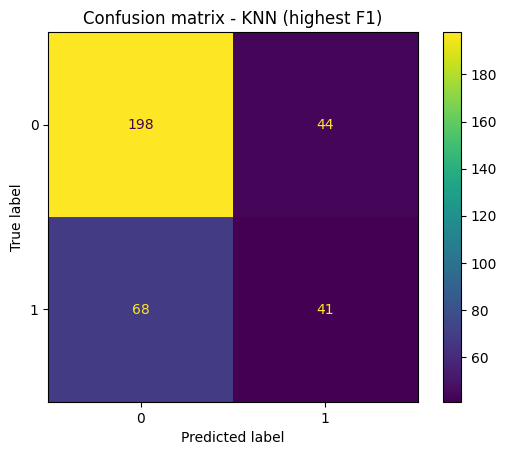

In [16]:
# knnn confusion matrix
best_pred = knn_pred
ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title("Confusion matrix - KNN (highest F1)")
plt.show()


KNN catches the highest proportion of high-arrears households, with a recall of 0.376. Even so, it missed 68 of the 109 households that truly had $3,000 or more in past-due rent. A missed case means a household in serious financial trouble is not flagged, so SLCM could overlook some of the most critical households and they might not get help in time.

7. Try a small GridSearchCV (15 points)
• Tune only two models on the training set with cv=3 and scoring="f1".
• For KNN, try n_neighbors = [3, 5, 7].
• For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100).
• Print best_params_ and best_score_ for each search. No extra charts or second search are needed.
• Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

In [18]:
#Try a small GridSearchCV (15 points) • Tune only two models on the training set with cv=3 and scoring="f1". • For KNN, try n_neighbors = [3, 5, 7]. • For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100). • Print best_params_ and best_score_ for each search
from sklearn.model_selection import GridSearchCV
knn_grid = GridSearchCV(knn, param_grid={"model__n_neighbors": [3, 5, 7]}, cv=3, scoring="f1")
knn_grid.fit(X_train, y_train)
print("KNN:")
print("Best params:", knn_grid.best_params_)
print("Best score:", knn_grid.best_score_)
#random forest
forest_grid = GridSearchCV(forest, param_grid={"model__max_depth": [3, 5, None]}, cv=3, scoring="f1")
forest_grid.fit(X_train, y_train)
print("Random Forest:")
print("Best params:", forest_grid.best_params_)
print("Best score:", forest_grid.best_score_)




KNN:
Best params: {'model__n_neighbors': 7}
Best score: 0.4854649923374277
Random Forest:
Best params: {'model__max_depth': None}
Best score: 0.4574743145651916


The KNN model has the higher best cross-validation F1 score of 0.4855, compared to Random Forest's score of 0.4575. KNN performed slightly better based on the cross-validation results.GridSearchCV is fitted on training data only to prevent data leakage. This keeps the test data unseen during model tuning, allowing us to evaluate how well the models perform on new, unseen data.

Part 4 – Explain the Results (15 points)


8. Interpret your comparison (8 points)
• In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not
accuracy alone.
• Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?


KNN is the most promising model because it had the highest test F1 score of 0.4227 and the highest recall of 0.3761. This means it performed better at identifying households with high rent arrears compared to the other models. A more complex model did not necessarily perform better, since Random Forest had the highest accuracy but lower F1 and recall than KNN. SLCM should pay close attention to false negatives because these represent households with high rent arrears that the model failed to identify. False positives also matter because they could lead to households being flagged when they do not actually have high arrears.

9. Recommendation to SLCM (7 points)
• Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model
performed, one practical insight, and one limitation.
• State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance

I recommend using KNN as a starting point to help SLCM identify households that may be struggling with high rent payments. The model was able to identify about 38% of the households that had $3,000 or more in past-due rent. This could help SLCM recognize some families who may need extra support. However, the model still misses many households, so it should only be used as an additional tool and not the only way to identify families in need. A prediction does not explain why a household is behind on rent and should never be used alone to decide who qualifies for assistance.